# 06 — Building the Science and Political Measures with PCA

Our research question asks whether attitudes to science and technology and political culture moderate the link between parental education and gender-role attitudes. Before we can test this in `07_moderation.ipynb`, we need measures of both. This notebook checks how the science items (Q158–Q163) and political items (Q241–Q253) group together, using item correlations, PCA and Cronbach's α, and then builds five measures.

In [17]:
from pathlib import Path

import pandas as pd
import numpy as np
from plotnine import *
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "code":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "WVS_Singapore_full_cleaned.csv"
TABLES = PROJECT_ROOT / "output" / "tables"
FIGURES = PROJECT_ROOT / "output" / "figures"

df = pd.read_csv(DATA_PATH)

We use Cronbach's α to check whether a group of items is answered consistently enough to be averaged into one score.

In [18]:
def cronbach_alpha(cols):
    items = df[cols].dropna()
    k = items.shape[1]
    return k / (k - 1) * (1 - items.var(ddof=1).sum() / items.sum(axis=1).var(ddof=1))


def run_pca(cols, name):
    work = df.dropna(subset=cols)
    X = StandardScaler().fit_transform(work[cols])
    pca = PCA().fit(X)
    pcs = [f"PC{i}" for i in range(1, len(cols) + 1)]
    prop = pca.explained_variance_ratio_
    variance = pd.DataFrame({"Standard deviation": pca.explained_variance_ ** 0.5,
                             "Proportion of variance": prop,
                             "Cumulative proportion": prop.cumsum()}, index=pcs).T
    loadings = pd.DataFrame(pca.components_.T, index=cols, columns=pcs)
    variance.to_csv(TABLES / f"pca_{name}_variance.csv")
    loadings.to_csv(TABLES / f"pca_{name}_loadings.csv")
    print(f"N = {len(work)}")
    return pca, variance, loadings


def scree_plot(pca, title, name, elbow):
    n = len(pca.explained_variance_ratio_)
    scree = pd.DataFrame({"component": range(1, n + 1), "percent": pca.explained_variance_ratio_ * 100})
    scree["label"] = scree["percent"].map(lambda p: f"{p:.1f}%")
    p = (
        ggplot(scree, aes("component", "percent"))
        + geom_col(fill="#4C78A8", width=0.7)
        + geom_line(aes(group=1))
        + geom_point()
        + geom_text(aes(label="label"), nudge_y=1.2, size=8, va="bottom")
        + geom_vline(xintercept=elbow, linetype="dashed", color="orangered")
        + scale_x_continuous(breaks=range(1, n + 1))
        + theme_light()
        + labs(x="Component", y="Percentage of variance explained", title=title,
               caption=f"Dashed line = elbow at component {elbow}")
    )
    p.save(FIGURES / f"pca_{name}_scree.png", dpi=300, verbose=False)
    return p

## 1. Science and technology items

All six items are coded so that higher = more positive about science (Q160–Q162 were reversed in 04).

In [19]:
science_items = ["Q158", "Q159", "Q160_rev", "Q161_rev", "Q162_rev", "Q163"]
science_corr = df[science_items].corr()
science_corr.to_csv(TABLES / "science_item_correlations.csv")
science_corr.round(2)

,Q158,Q159,Q160_rev,Q161_rev,Q162_rev,Q163
Q158,1.00,0.70,-0.05,0.04,0.21,0.30
Q159,0.70,1.00,-0.03,0.01,0.13,0.33
Q160_rev,-0.05,-0.03,1.00,0.54,0.03,-0.15
Q161_rev,0.04,0.01,0.54,1.00,0.08,-0.14
Q162_rev,0.21,0.13,0.03,0.08,1.00,-0.01
Q163,0.30,0.33,-0.15,-0.14,-0.01,1.00


In [20]:
print(f"Cronbach's alpha, all six science items = {cronbach_alpha(science_items):.3f}")

Cronbach's alpha, all six science items = 0.460


For all six items α = .460, far too low to treat them as one score. The correlations show why: Q158, Q159 and Q163 correlate with each other (r = .30 to .70), Q160_rev and Q161_rev correlate with each other (r = .54), but the two groups are barely related (r = −.15 to .04). Q162_rev is only weakly related to any item (r ≤ .21).

We standardise each item with `StandardScaler` before the PCA, because variables with larger spreads would otherwise dominate the components.

In [21]:
sci_pca, sci_variance, sci_loadings = run_pca(science_items, "science_items")
sci_variance.round(3)

N = 1977


,PC1,PC2,PC3,PC4,PC5,PC6
Standard deviation,1.413,1.261,0.985,0.838,0.674,0.539
Proportion of variance,0.333,0.265,0.162,0.117,0.076,0.048
Cumulative proportion,0.333,0.598,0.759,0.876,0.952,1.000


In [22]:
sci_loadings.round(3)

,PC1,PC2,PC3,PC4,PC5,PC6
Q158,0.607,0.171,0.008,-0.321,0.054,0.704
Q159,0.607,0.151,-0.109,-0.317,-0.126,-0.693
Q160_rev,-0.159,0.650,-0.213,0.138,-0.691,0.098
Q161_rev,-0.104,0.677,-0.134,0.084,0.706,-0.089
Q162_rev,0.197,0.214,0.886,0.349,-0.058,-0.068
Q163,0.433,-0.147,-0.373,0.806,0.042,0.030


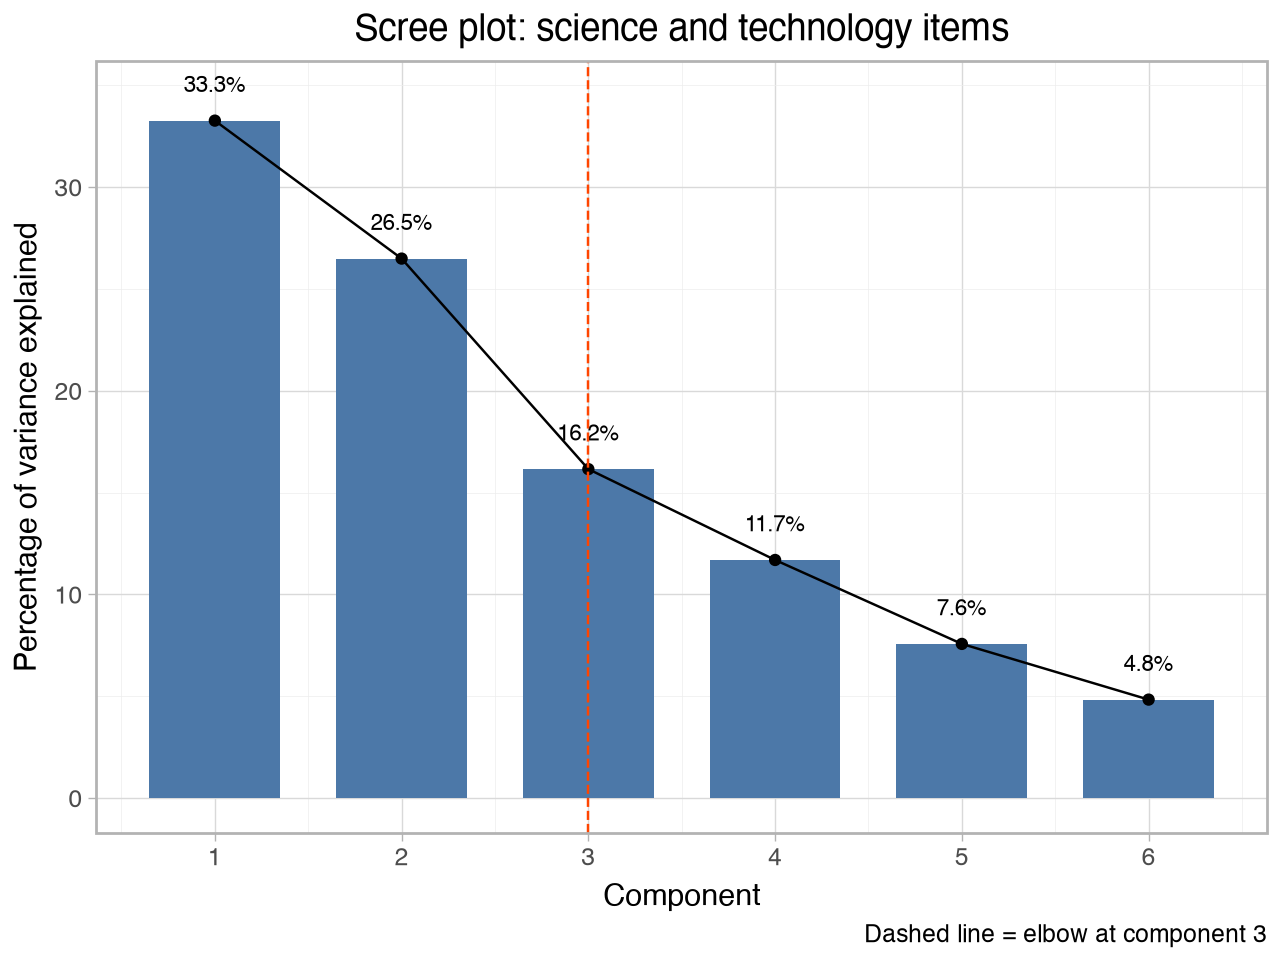

In [23]:
scree_plot(sci_pca, "Scree plot: science and technology items", "science_items", elbow=3)

PC1 (33.3% of the variance) loads mainly on Q158, Q159 and Q163 (0.43 to 0.61), and PC2 (26.5%) on Q160_rev and Q161_rev (0.65 and 0.68). The scree plot flattens from PC3, which is almost entirely Q162_rev (0.886), so we keep the two components before the elbow (59.8% together). This confirms the two groups seen in the correlations: optimism about science's benefits, and concern about its effects on faith and morality.

In [24]:
science_measures = {"science_optimism": ["Q158", "Q159", "Q163"],
                    "science_faith_morality": ["Q160_rev", "Q161_rev"]}
for name, cols in science_measures.items():
    df[name] = df[cols].mean(axis=1, skipna=False)
    print(f"{name}: alpha = {cronbach_alpha(cols):.3f}")

science_optimism: alpha = 0.698
science_faith_morality: alpha = 0.705


Both measures have acceptable reliability (science optimism α = .698, science and faith/morality α = .705). Q162 is left out because it is unrelated to both groups and forms its own component, so it seems to measure personal interest in science rather than a view of its effects.

## 2. Political culture items

In [25]:
political_items = [f"Q{i}" for i in range(241, 249)] + ["Q250", "Q251", "Q252", "Q253_rev"]
political_corr = df[political_items].corr()
political_corr.to_csv(TABLES / "political_item_correlations.csv")
political_corr.round(2)

,Q241,Q242,Q243,Q244,Q245,Q246,Q247,Q248,Q250,Q251,Q252,Q253_rev
Q241,1.00,0.18,0.16,0.36,0.13,0.20,0.27,0.17,0.18,0.06,0.07,0.01
Q242,0.18,1.00,-0.24,0.16,0.36,-0.12,0.35,0.26,-0.06,0.05,0.02,-0.02
Q243,0.16,-0.24,1.00,0.12,-0.12,0.42,-0.02,0.02,0.24,0.10,0.12,0.06
Q244,0.36,0.16,0.12,1.00,0.21,0.23,0.38,0.27,0.13,0.07,0.07,0.02
Q245,0.13,0.36,-0.12,0.21,1.00,-0.03,0.28,0.29,0.02,0.10,0.09,0.03
Q246,0.20,-0.12,0.42,0.23,-0.03,1.00,0.16,0.09,0.14,0.02,0.06,0.06
Q247,0.27,0.35,-0.02,0.38,0.28,0.16,1.00,0.33,0.04,0.04,0.06,0.03
Q248,0.17,0.26,0.02,0.27,0.29,0.09,0.33,1.00,0.11,0.24,0.24,0.15
Q250,0.18,-0.06,0.24,0.13,0.02,0.14,0.04,0.11,1.00,0.34,0.21,0.09
Q251,0.06,0.05,0.10,0.07,0.10,0.02,0.04,0.24,0.34,1.00,0.66,0.41


Three content groups stand out. The authoritarian items (Q242, Q245, Q248) correlate .26 to .36 with each other, the liberal items (Q243, Q246) correlate .42 and are unrelated or negatively related to Q242 and Q245 (−.24 to −.03), and the two regime-evaluation items (Q251, Q252) correlate .66.

Q253 is on a 1–4 scale while the other items run from 1 to 10, which is another reason to standardise before the PCA.

In [26]:
pol_pca, pol_variance, pol_loadings = run_pca(political_items, "political_items")
pol_variance.round(3)

N = 1755


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12
Standard deviation,1.635,1.404,1.314,0.963,0.890,0.836,0.805,0.794,0.762,0.726,0.720,0.560
Proportion of variance,0.223,0.164,0.144,0.077,0.066,0.058,0.054,0.053,0.048,0.044,0.043,0.026
Cumulative proportion,0.223,0.387,0.531,0.608,0.674,0.732,0.786,0.839,0.887,0.931,0.974,1.000


In [27]:
pol_loadings.iloc[:, :4].round(3)

,PC1,PC2,PC3,PC4
Q241,0.303,0.156,0.290,0.246
Q242,0.240,0.396,-0.256,0.075
Q243,0.103,-0.282,0.494,-0.090
Q244,0.326,0.227,0.281,-0.020
Q245,0.275,0.295,-0.195,0.074
Q246,0.177,-0.097,0.513,-0.376
Q247,0.340,0.330,0.079,-0.213
Q248,0.378,0.126,-0.101,-0.126
Q250,0.228,-0.244,0.179,0.735
Q251,0.362,-0.381,-0.256,0.125


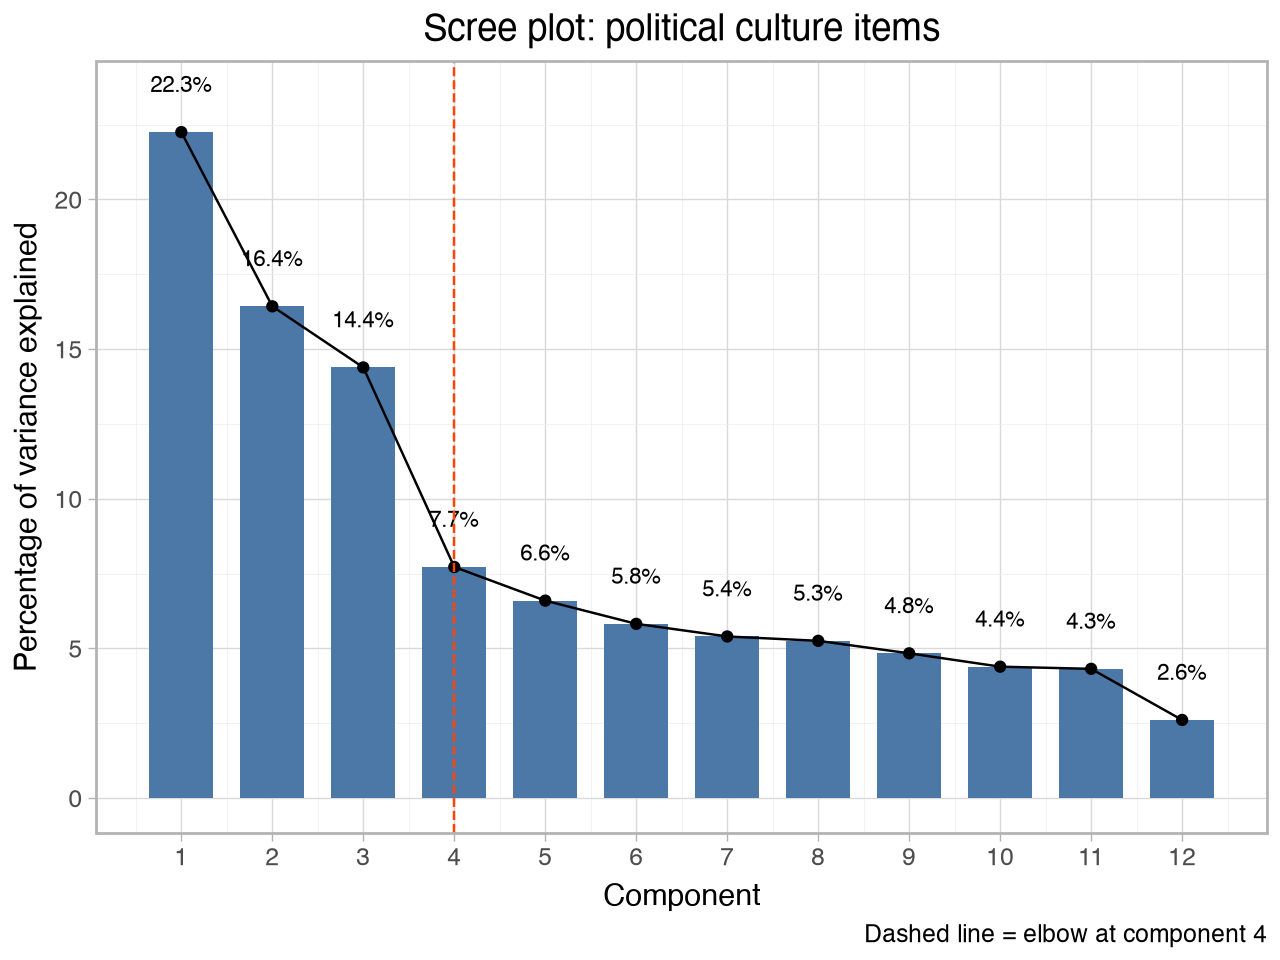

In [28]:
scree_plot(pol_pca, "Scree plot: political culture items", "political_items", elbow=4)

The scree plot drops sharply after PC3 (14.4% to 7.7%), so we keep three components (53.1% together). PC1 (22.3%) has positive loadings for every item, a general tendency to rate everything highly. PC2 (16.4%) contrasts the authoritarian items (Q242 0.396, Q245 0.295) with regime evaluation (Q251 and Q252 −0.381), and PC3 (14.4%) contrasts the liberal items (Q243 0.494, Q246 0.513) with the authoritarian items (Q242 −0.256, Q245 −0.195). This supports keeping the authoritarian, liberal and regime-evaluation groups separate.

In [29]:
candidates = {"Authoritarian (Q242, Q245, Q248)": ["Q242", "Q245", "Q248"],
              "Liberal (Q243, Q246)": ["Q243", "Q246"],
              "Regime evaluation (Q251, Q252)": ["Q251", "Q252"]}
candidate_alphas = pd.DataFrame({"N (complete cases)": [len(df[c].dropna()) for c in candidates.values()],
                                 "Cronbach's alpha": [cronbach_alpha(c) for c in candidates.values()]},
                                index=candidates.keys())
candidate_alphas.to_csv(TABLES / "political_candidate_alphas.csv")
candidate_alphas.round(3)

,N (complete cases),Cronbach's alpha
"Authoritarian (Q242, Q245, Q248)",1827,0.569
"Liberal (Q243, Q246)",1872,0.592
"Regime evaluation (Q251, Q252)",1955,0.797


Regime evaluation is reliable (α = .797), but the authoritarian (α = .569) and liberal (α = .592) groups fall below .70, partly because they have only three and two items. We still build them because their content and the PCA support them, but they are rough measures and results involving them should be read with care.

In [30]:
political_measures = {"authoritarian_democracy": ["Q242", "Q245", "Q248"],
                      "liberal_democracy": ["Q243", "Q246"],
                      "regime_evaluation": ["Q251", "Q252"]}
for name, cols in political_measures.items():
    df[name] = df[cols].mean(axis=1, skipna=False)

Q249 ("women have the same rights as men") is left out because it overlaps with our outcome, so it would partly use gender-role attitudes to predict gender-role attitudes. Q240 (left–right self-placement) stays a single item because it measures ideology rather than views of democracy and did not group with the other items.

## 3. The five measures

In [31]:
all_measures = {**science_measures, **political_measures}
higher_means = {
    "science_optimism": "More optimistic about the benefits of science",
    "science_faith_morality": "Less worried that science undermines faith and morality",
    "authoritarian_democracy": "More likely to see authoritarian features as essential to democracy",
    "liberal_democracy": "More likely to see free elections and civil rights as essential to democracy",
    "regime_evaluation": "More positive view of how democratic and satisfactory Singapore's system is",
}
measures_table = pd.DataFrame({
    "Items": [", ".join(c) for c in all_measures.values()],
    "Higher score means": [higher_means[m] for m in all_measures],
    "Cronbach's alpha": [cronbach_alpha(c) for c in all_measures.values()],
    "Mean": [df[m].mean() for m in all_measures],
    "SD": [df[m].std() for m in all_measures],
}, index=pd.Index(all_measures.keys(), name="Measure"))
measures_table.to_csv(TABLES / "moderator_measures_summary.csv")
measures_table.round(3)

,Items,Higher score means,Cronbach's alpha,Mean,SD
Measure,,,,,
science_optimism,"Q158, Q159, Q163",More optimistic about the benefits of science,0.698,7.096,1.558
science_faith_morality,"Q160_rev, Q161_rev",Less worried that science undermines faith and...,0.705,5.320,2.000
authoritarian_democracy,"Q242, Q245, Q248",More likely to see authoritarian features as e...,0.569,4.124,1.790
liberal_democracy,"Q243, Q246",More likely to see free elections and civil ri...,0.592,7.649,1.833
regime_evaluation,"Q251, Q252",More positive view of how democratic and satis...,0.797,6.735,1.697


In [32]:
df.to_csv(DATA_PATH, index=False)
print(f"Saved {len(all_measures)} measures to {DATA_PATH.name}")

Saved 5 measures to WVS_Singapore_full_cleaned.csv


Respondents are optimistic about science (mean 7.10) but split on its moral effects (5.32, near the middle of the scale). On average they reject authoritarian features as part of democracy (4.12), see liberal features as essential (7.65) and rate Singapore's political system fairly positively (6.74).

## Summary

- The six science items do not form one scale (α = .460); PCA shows two components before the elbow (59.8% of the variance).
- `science_optimism` (Q158, Q159, Q163; α = .698) and `science_faith_morality` (Q160_rev, Q161_rev; α = .705) are built; Q162 is left out.
- The political PCA keeps three components (53.1%), separating authoritarian, liberal and regime-evaluation items.
- `authoritarian_democracy` (α = .569), `liberal_democracy` (α = .592) and `regime_evaluation` (α = .797) are built; Q249 is excluded and Q240 stays a single item.
- All five measures are saved to `WVS_Singapore_full_cleaned.csv` for `07_moderation.ipynb` and `08_multivariate_models.ipynb`.